# P4 — Listening Past the Noise
### Noisy-label audio classification with classical ML (MAP@3)

**Notebook layout (matches the report requirements)**

| Part | Content |
|---|---|
| 0 | Setup, data loading |
| 1 | Data audit: label quality, class sizes, durations |
| 2 | Feature extraction (single-STFT, parallel, cached) |
| 3 | Shared tooling: MAP@3, models, cross-validation, prior and noise tools |
| 4 | **Model 1 – Baseline** (verified labels only, 89 features, 4-model ensemble) |
| 5 | Diagnosis: hypotheses for the gap between CV (≈0.72) and the leaderboard (0.695) |
| 6 | Noise analysis of the unchecked labels |
| 7 | **Model 2 – + unchecked data (noise-filtered) + prior correction** |
| 8 | **Model 3 – + richer features, tuned ensemble** |
| 9 | Error analysis, limitations, final summary and submission files |

**Output files** (`/kaggle/working/`): exactly one Kaggle upload file, `submission.csv` (columns `id,label`, 1,592 rows, 1–3 codes per row) = the best model by CV (change `SUBMIT_CHOICE` in Section 10 to pick another).
The three model CSVs required by the report are in `/kaggle/working/model_files/`: `submission_model1_baseline.csv`, `submission_model2.csv`, `submission_model3.csv` (+ a few Model-3 prior variants for leaderboard probing).

**Rules followed:** only the competition files; librosa features; SVM / LR / RF / ExtraTrees; noisy-label methods built from those models (cross-validated filtering, sample weighting, EM over the true label); no pretrained models, no deep learning, no hand-labelling.

## 0. Setup

In [1]:
import os, time, warnings
from pathlib import Path
import numpy as np, pandas as pd
import soundfile as sf, librosa
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
warnings.filterwarnings("ignore")

INPUT_ROOT = Path(os.environ.get("P4_INPUT", "/kaggle/input"))
WORK       = Path(os.environ.get("P4_WORK", "/kaggle/working")); WORK.mkdir(parents=True, exist_ok=True)
N_JOBS     = int(os.environ.get("P4_JOBS", -1))      # -1 = all cores
SEEDS      = [42, 2026]                              # CV seeds (grid on the first, confirmation on the second)

train_csv = list(INPUT_ROOT.rglob("train.csv")); assert len(train_csv) == 1, train_csv
DATA = train_csv[0].parent
train_df  = pd.read_csv(DATA/"train.csv", dtype={"id": str})   # dtype=str: ids like '12345678' must stay strings
test_df   = pd.read_csv(DATA/"test.csv",  dtype={"id": str})
sample_df = pd.read_csv(DATA/"sample_submission.csv", dtype={"id": str})
TRAIN_AUDIO = list(INPUT_ROOT.rglob("audio/train")); TEST_AUDIO = list(INPUT_ROOT.rglob("audio/test"))
assert len(TRAIN_AUDIO) == 1 and len(TEST_AUDIO) == 1
TRAIN_AUDIO, TEST_AUDIO = TRAIN_AUDIO[0], TEST_AUDIO[0]
EXPECTED_TEST = int(os.environ.get("P4_EXPECTED_TEST", 1592))
assert test_df["id"].is_unique and sample_df["id"].is_unique and train_df["id"].is_unique
assert set(test_df["id"]) == set(sample_df["id"]), "test.csv and sample_submission.csv ids differ"
assert len(test_df) == EXPECTED_TEST, len(test_df)
print("data dir:", DATA); print(train_df.shape, test_df.shape, sample_df.shape)
print("train wav:", len(list(TRAIN_AUDIO.glob('*.wav'))), "| test wav:", len(list(TEST_AUDIO.glob('*.wav'))))

data dir: /kaggle/input/competitions/project4
(5604, 3) (1592, 1) (1592, 2)
train wav: 5604 | test wav: 1592


## 1. Data audit

Facts that drive every design decision below:

* **41 categories.** Only `checked == 1` labels are guaranteed correct; test labels are all checked.
* The checked samples are the **only clean validation set**, and unchecked labels are noisy (an unknown share are wrong, different per class).
* Verified counts per class are *not* equal: most classes have 10, but a handful have 40. Those handful are also the **smallest** classes overall.
* The test set is smaller and has shorter recordings on average than the training set.

In [2]:
classes = np.array(sorted(train_df["label"].unique())); K = len(classes)
cls_idx = {c: i for i, c in enumerate(classes)}
verified_mask = (train_df["checked"].values == 1)
y_all_idx = train_df["label"].map(cls_idx).values
y_ver_idx = y_all_idx[verified_mask];  y_unc_idx = y_all_idx[~verified_mask]
yv, yu = y_ver_idx, y_unc_idx

tab = pd.DataFrame({
    "verified":  np.bincount(yv, minlength=K),
    "unchecked": np.bincount(yu, minlength=K)}, index=classes)
tab["total"] = tab.verified + tab.unchecked
ver_cnt = tab.verified.values.astype(float)
print("classes:", K, "| verified:", verified_mask.sum(), "| unchecked:", (~verified_mask).sum())
print("verified-per-class value counts:", tab.verified.value_counts().to_dict())
big = tab.index[tab.verified == tab.verified.max()].tolist()
print("classes with the larger verified quota:", big)
print("share of verified samples in those classes: %.1f%%   share of ALL train samples in them: %.1f%%" % (
      100*tab.loc[big,'verified'].sum()/tab.verified.sum(), 100*tab.loc[big,'total'].sum()/tab.total.sum()))
display(tab.T)

classes: 41 | verified: 620 | unchecked: 4984
verified-per-class value counts: {10: 34, 40: 7}
classes with the larger verified quota: ['C03', 'C05', 'C10', 'C14', 'C36', 'C38', 'C39']
share of verified samples in those classes: 45.2%   share of ALL train samples in them: 8.1%


,C01,C02,C03,C04,C05,C06,C07,C08,C09,C10,...,C32,C33,C34,C35,C36,C37,C38,C39,C40,C41
verified,10,10,40,10,40,10,10,10,10,40,...,10,10,10,10,40,10,40,40,10,10
unchecked,162,48,2,214,40,79,206,52,171,21,...,56,152,211,63,47,183,29,8,45,130
total,172,58,42,224,80,89,216,62,181,61,...,66,162,221,73,87,193,69,48,55,140


## 2. Feature extraction

The baseline recomputed an STFT for every feature (~15 min serial). Here **one STFT per file** is shared by all features and files are processed in parallel with `joblib`, and the result is cached.

Feature blocks (column order is fixed):

1. `base75` – exactly the baseline features: MFCC(20) mean/std, chroma(12) mean/std, centroid/bandwidth/rolloff/ZCR/RMS mean/std, duration.
2. `contrast14` – spectral contrast (7 bands) mean/std. (`base75 + contrast14 = 89` = the baseline set.)
3. `rich` – new: 40-band log-mel statistics (mean, std, 90th percentile, max) and MFCC statistics computed **only on active (non-silent) frames**, delta-MFCC std, spectral flatness, onset strength, onset rate, RMS percentiles, active-frame ratio, log-duration. The recordings contain silence and background noise, so active-frame statistics and "peakiness" (max / p90) should separate transient sounds from steady ones better than plain means.

In [3]:
SR, N_FFT, HOP = 22050, 2048, 512

def extract_one(path):
    try:
        y, sr = sf.read(str(path), dtype="float32")
        if y.ndim > 1: y = y.mean(axis=1)
        dur = len(y) / sr
        if len(y) < N_FFT: y = np.pad(y, (0, N_FFT - len(y)))
        S  = np.abs(librosa.stft(y, n_fft=N_FFT, hop_length=HOP)); P2 = S ** 2     # one STFT for everything
        rms  = librosa.feature.rms(y=y, frame_length=N_FFT, hop_length=HOP)
        zcr  = librosa.feature.zero_crossing_rate(y=y, frame_length=N_FFT, hop_length=HOP)
        mel128 = librosa.feature.melspectrogram(S=P2, sr=sr, n_mels=128)
        mfcc = librosa.feature.mfcc(S=librosa.power_to_db(mel128), n_mfcc=20)
        chroma = librosa.feature.chroma_stft(S=P2, sr=sr)
        cent = librosa.feature.spectral_centroid(S=S, sr=sr)
        bw   = librosa.feature.spectral_bandwidth(S=S, sr=sr)
        roll = librosa.feature.spectral_rolloff(S=S, sr=sr)
        con  = librosa.feature.spectral_contrast(S=S, sr=sr)
        ms = lambda M: np.concatenate([M.mean(axis=1), M.std(axis=1)])
        base = np.concatenate([ms(mfcc), ms(chroma), ms(cent), ms(bw), ms(roll), ms(zcr), ms(rms), [dur]])   # 75
        contrast = ms(con)                                                                                       # 14

        # ---- rich block
        r1 = rms[0]; T = S.shape[1]
        act = r1 >= max(np.percentile(r1, 30), 0.02 * r1.max())
        if act.sum() < 3: act = np.ones(T, bool)
        lm  = librosa.power_to_db(librosa.feature.melspectrogram(S=P2, sr=sr, n_mels=40))     # (40, T)
        lma, mfa = lm[:, act], mfcc[:, act]
        dm  = librosa.feature.delta(mfcc, width=9 if T >= 9 else 3, mode="nearest")
        flat = librosa.feature.spectral_flatness(S=S)[0]
        env  = librosa.onset.onset_strength(S=lm, sr=sr, hop_length=HOP)
        n_on = len(librosa.onset.onset_detect(onset_envelope=env, sr=sr, hop_length=HOP))
        lr = np.log(r1 + 1e-8)
        rich = np.concatenate([
            lma.mean(1), lma.std(1), np.percentile(lma, 90, axis=1), lm.max(1),
            mfa.mean(1), mfa.std(1), dm.std(1),
            [flat.mean(), flat.std(), env.mean(), env.std()],
            np.percentile(lr, [10, 50, 90]),
            [act.mean(), np.log(dur + 1e-3), n_on / max(dur, 1e-3)]])
        return np.concatenate([base, contrast, rich]).astype(np.float32)
    except Exception as e:
        return None

def extract_all(ids, folder):
    rows = Parallel(n_jobs=N_JOBS, batch_size=8, verbose=5)(delayed(extract_one)(folder / f"{i}.wav") for i in ids)
    dim = next(r.shape[0] for r in rows if r is not None)
    bad = [i for i, r in zip(ids, rows) if r is None]
    X = np.vstack([r if r is not None else np.full(dim, np.nan, np.float32) for r in rows])
    print(f"{folder.name}: {X.shape}, failed files: {len(bad)}", bad[:5]); return X

import hashlib, inspect
FEATURE_VERSION = "v3"      # bump this by hand too if you change anything the hash cannot see (e.g. constants SR/N_FFT/HOP)
try:    _src = inspect.getsource(extract_one)
except Exception: _src = ""
FEAT_HASH = hashlib.md5((FEATURE_VERSION + _src + str((SR, N_FFT, HOP))).encode()).hexdigest()[:10]
FEAT_FILE = WORK / f"p4_features_{FEAT_HASH}.npz"      # new extraction code => new hash => new file => old cache is never reused
print("feature cache file:", FEAT_FILE.name)
if FEAT_FILE.exists():
    z = np.load(FEAT_FILE, allow_pickle=True)
    if list(z["train_ids"]) == train_df["id"].tolist() and list(z["test_ids"]) == test_df["id"].tolist():
        Xtr_all, Xte_all = z["Xtr"], z["Xte"]; print("loaded cached features", Xtr_all.shape, Xte_all.shape)
if "Xtr_all" not in globals():
    t0 = time.time()
    Xtr_all = extract_all(train_df["id"].tolist(), TRAIN_AUDIO)
    Xte_all = extract_all(test_df["id"].tolist(),  TEST_AUDIO)
    np.savez_compressed(FEAT_FILE, Xtr=Xtr_all, Xte=Xte_all,
                        train_ids=np.array(train_df["id"]), test_ids=np.array(test_df["id"]))
    print("extraction time: %.0fs" % (time.time() - t0))

# clean: inf -> nan -> train median
Xtr_all = np.where(np.isfinite(Xtr_all), Xtr_all, np.nan); Xte_all = np.where(np.isfinite(Xte_all), Xte_all, np.nan)
med = np.nanmedian(Xtr_all, axis=0)
Xtr_all = np.where(np.isnan(Xtr_all), med, Xtr_all); Xte_all = np.where(np.isnan(Xte_all), med, Xte_all)
D = Xtr_all.shape[1]; print("total feature dim:", D)
assert D > 89

FEATS = {"F89":  (Xtr_all[:, :89], Xte_all[:, :89]),     # baseline feature set (75 + 14 contrast)
         "Frich": (Xtr_all,        Xte_all)}             # + rich block
XV = {k: v[0][verified_mask] for k, v in FEATS.items()}
XU = {k: v[0][~verified_mask] for k, v in FEATS.items()}
XT = {k: v[1] for k, v in FEATS.items()}
dur_tr, dur_te = Xtr_all[:, 74], Xte_all[:, 74]
print("duration (s)  verified: %.2f | unchecked: %.2f | test: %.2f" % (dur_tr[verified_mask].mean(), dur_tr[~verified_mask].mean(), dur_te.mean()))

feature cache file: p4_features_2e645391c6.npz


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=-1)]: Done  88 tasks      | elapsed:   34.7s
[Parallel(n_jobs=-1)]: Done 520 tasks      | elapsed:   47.4s
[Parallel(n_jobs=-1)]: Done 1240 tasks      | elapsed:  1.1min
[Parallel(n_jobs=-1)]: Done 2248 tasks      | elapsed:  1.5min
[Parallel(n_jobs=-1)]: Done 3544 tasks      | elapsed:  2.1min
/usr/local/lib/python3.13/dist-packages/librosa/core/pitch.py:103: UserWarning: Trying to estimate tuning from empty frequency set.
  return pitch_tuning(
[Parallel(n_jobs=-1)]: Done 5128 tasks      | elapsed:  2.9min
[Parallel(n_jobs=-1)]: Done 5604 out of 5604 | elapsed:  3.1min finished
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 4 concurrent workers.


train: (5604, 319), failed files: 0 []


[Parallel(n_jobs=-1)]: Done  88 tasks      | elapsed:    1.9s
/usr/local/lib/python3.13/dist-packages/librosa/core/pitch.py:103: UserWarning: Trying to estimate tuning from empty frequency set.
  return pitch_tuning(
[Parallel(n_jobs=-1)]: Done 520 tasks      | elapsed:   10.8s
[Parallel(n_jobs=-1)]: Done 1240 tasks      | elapsed:   25.6s
[Parallel(n_jobs=-1)]: Done 1592 out of 1592 | elapsed:   31.9s finished


test: (1592, 319), failed files: 0 []
extraction time: 218s
total feature dim: 319
duration (s)  verified: 5.61 | unchecked: 8.16 | test: 5.49


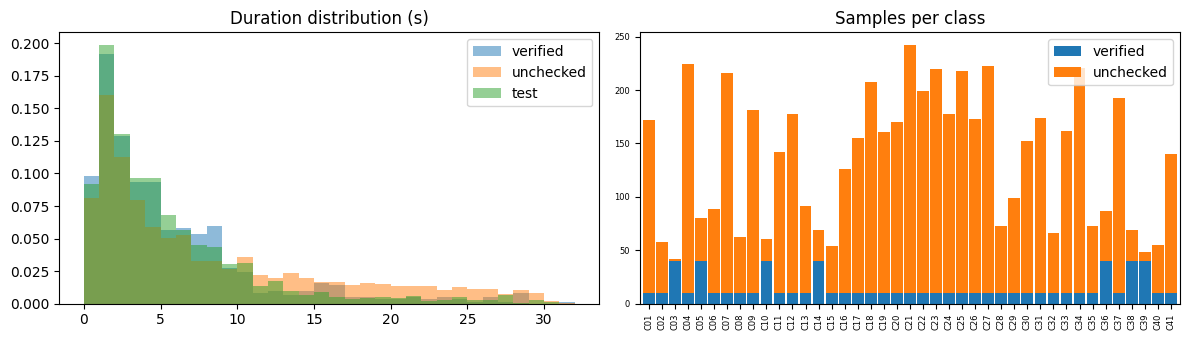

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
bins = np.linspace(0, 32, 33)
for lab, d in [("verified", dur_tr[verified_mask]), ("unchecked", dur_tr[~verified_mask]), ("test", dur_te)]:
    ax[0].hist(d, bins=bins, alpha=.5, density=True, label=lab)
ax[0].set_title("Duration distribution (s)"); ax[0].legend()
tab[["verified", "unchecked"]].plot.bar(stacked=True, ax=ax[1], width=.9); ax[1].set_title("Samples per class"); ax[1].tick_params(labelsize=6)
plt.tight_layout(); plt.show()

## 3. Shared tooling

* **MAP@3** and **simulated test sets.** The verified set is class-imbalanced (10 vs 40 per class) while the test set may not be. To see how a pipeline would behave under other class mixes, validation predictions are *resampled* so that class frequencies follow (a) the class sizes in `train.csv` or (b) a uniform mix. Both are **assumptions**, never facts, so every number is reported next to the plain CV score.
* **Cross-fitted temperature calibration:** ensemble probabilities are sharpened with one scalar temperature. For each validation fold the temperature is fitted on the *other* folds' out-of-fold predictions only, so a label is never used both to calibrate and to score the same prediction.
* **EM prior correction (the same procedure in CV and for the real test set):** models trained with `class_weight="balanced"` output posteriors under a ~uniform prior. The class prior of an *unlabelled* set is estimated by EM (Saerens et al.) from the calibrated predictions and the posteriors are multiplied by `prior^power`. In CV this is run on each simulated test set; on the real test set it is run on the test predictions.
* **EM over the true label** for unchecked samples: estimates a class-conditional noise matrix (with pseudo-counts so small classes cannot collapse) and, per sample, the posterior that the given label is correct.
* **Cross-validated filtering:** unchecked samples are only kept when a model trained on *verified data of the training fold only* agrees with the given label, so nothing leaks into the validation fold.

In [6]:
# ---------- metrics
def map3_s(yi, P):
    top3 = np.argsort(-P, axis=1)[:, :3]
    return ((top3 == yi[:, None]) / np.array([1., 2., 3.])).sum(1)
def wmap3(yi, P, w=None): return float(np.average(map3_s(yi, P), weights=w))

# ---------- priors
tot = tab.total.values.astype(float)
pi_target = tot / tot.sum()                 # proxy for the test class prior (class size in train.csv)
pi_ver    = ver_cnt / ver_cnt.sum()
w_val  = (pi_target / pi_ver)[yv]           # importance weights: verified distribution -> proxy test distribution
w_unif = (1.0 / pi_ver)[yv]                 # weights: verified distribution -> uniform (used to calibrate balanced models)

def adjust(P, pi):
    Q = P * pi[None, :]; return Q / Q.sum(1, keepdims=True)
def sharpen(P, t):
    Q = np.clip(P, 1e-9, None) ** t; return Q / Q.sum(1, keepdims=True)
def fit_temp(P, yi, w=None):
    best = (1e9, 1.0)
    for t in np.linspace(0.5, 5.0, 19):
        Q = sharpen(P, t); nll = -np.average(np.log(Q[np.arange(len(yi)), yi] + 1e-12), weights=w)
        if nll < best[0]: best = (nll, t)
    return best[1]
def em_prior(P, iters=200, floor=0.25):
    # P: calibrated posteriors under a uniform prior -> estimated class prior of the (unlabelled) set
    pi = np.full(K, 1.0 / K)
    for _ in range(iters):
        Q = P * (pi * K)[None, :]; Q /= Q.sum(1, keepdims=True); pi = Q.mean(0)
    pi = np.clip(pi, floor / K, None); return pi / pi.sum()
def em_noise(P, yi, iters=40):
    # EM over the true label of noisy-labelled samples. P: calibrated posteriors p(k|x) (uniform prior).
    n = len(yi); Y = np.eye(K)[yi]
    T0 = np.full((K, K), 0.5 / (K - 1)); np.fill_diagonal(T0, 0.5); T = T0.copy(); pi = np.full(K, 1.0 / K)
    for _ in range(iters):
        Q = P * (pi * K)[None, :] * T[:, yi].T
        Q /= Q.sum(1, keepdims=True)
        pi = Q.mean(0)
        Tn = Q.T @ Y + 5.0 * T0                       # 5 pseudo-samples per class: stops tiny classes collapsing to purity ~0
        T = Tn / Tn.sum(1, keepdims=True)
    return T, Q, pi

# ---------- models
def make_models(kind, n_jobs=1):
    # returns [(name, estimator, sample_weight_kwarg, ensemble_weight)]
    rf = lambda n, s: RandomForestClassifier(n_estimators=n, class_weight="balanced", min_samples_leaf=2, random_state=s, n_jobs=n_jobs)
    et = lambda n, s: ExtraTreesClassifier(n_estimators=n, class_weight="balanced", min_samples_leaf=2, random_state=s, n_jobs=n_jobs)
    svm = lambda C: make_pipeline(StandardScaler(), SVC(C=C, kernel="rbf", gamma="scale", class_weight="balanced", probability=True, random_state=42))
    lr  = lambda C: make_pipeline(StandardScaler(), LogisticRegression(C=C, class_weight="balanced", max_iter=3000))
    if kind == "orig":      # the baseline ensemble (weights 40/10/30/20 found by the baseline CV)
        return [("svm", svm(3), "svc__sample_weight", .40), ("lr", lr(1.0), "logisticregression__sample_weight", .10),
                ("rf", rf(400, 42), "sample_weight", .30), ("et", et(400, 42), "sample_weight", .20)]
    if kind == "rich":      # wider features: stronger regularised LR, two SVMs, more trees
        return [("svm3", svm(3), "svc__sample_weight", .25), ("svm10", svm(10), "svc__sample_weight", .15),
                ("lr", lr(0.1), "logisticregression__sample_weight", .10),
                ("rf", rf(500, 42), "sample_weight", .25), ("et", et(500, 42), "sample_weight", .25)]
    raise ValueError(kind)

def fit_predict(Xtr, ytr, wtr, X_list, kind, n_jobs=1):
    outs = [np.zeros((len(X), K)) for X in X_list]
    for name, m, wk, a in make_models(kind, n_jobs):
        if wtr is None: m.fit(Xtr, ytr)
        else:           m.fit(Xtr, ytr, **{wk: wtr})
        for o, X in zip(outs, X_list): o[:, m.classes_] += a * m.predict_proba(X)
    return outs

# ---------- cross-validation, stage 1 = verified-only models (this IS the baseline CV)
def stage1(feat, kind, seed):
    Xv, Xu = XV[feat], XU[feat]
    splits = list(StratifiedKFold(5, shuffle=True, random_state=seed).split(Xv, yv))
    def one(tr, va): return fit_predict(Xv[tr], yv[tr], None, [Xu, Xv[va]], kind, 1)
    res = Parallel(n_jobs=N_JOBS)(delayed(one)(tr, va) for tr, va in splits)
    oof = np.zeros((len(yv), K))
    for (tr, va), (Pu, Pva) in zip(splits, res): oof[va] = Pva
    return dict(splits=splits, Pu=[r[0] for r in res], oof=oof)
ST1 = {}
def get_st(feat, kind, seed):
    if (feat, kind, seed) not in ST1: ST1[(feat, kind, seed)] = stage1(feat, kind, seed)
    return ST1[(feat, kind, seed)]
def final_temp(feat, kind):
    # temperature used for the FINAL test predictions: fitted on all out-of-fold predictions of both seeds (no scoring happens with it)
    return float(np.mean([fit_temp(get_st(feat, kind, s)["oof"], yv, w_unif) for s in SEEDS]))

# ---------- selection of unchecked samples
def select_unc(Pu, cfg, temp):
    n = len(yu); s = Pu[np.arange(n), yu]
    if cfg["method"] == "agree":                       # keep if the given label is (near) the model's top choice
        rank = (Pu > s[:, None]).sum(1)
        keep = (rank < cfg["max_rank"]) & (s >= cfg.get("tau", 0.0)); w = np.full(n, cfg["w"])
    else:                                              # EM over the true label: keep if P(given label is correct) is high
        T, Q, pi = em_noise(sharpen(Pu, temp), yu)
        q = Q[np.arange(n), yu]; keep = q >= cfg["q_min"]; w = cfg["w"] * q
    return keep, w

def stage2(feat, kind, st, cfg):
    Xv, Xu, oof1 = XV[feat], XU[feat], st["oof"]
    def one(tr, va, Pu):
        # (1) the EM temperature for THIS fold is fitted only on the OTHER folds' out-of-fold predictions
        temp = fit_temp(oof1[tr], yv[tr], w_unif[tr]) if cfg["method"] == "em" else None
        keep, w = select_unc(Pu, cfg, temp)
        Xa = np.vstack([Xv[tr], Xu[keep]]); ya = np.concatenate([yv[tr], yu[keep]])
        wa = np.concatenate([np.ones(len(tr)), w[keep]])
        return fit_predict(Xa, ya, wa, [Xv[va]], kind, 1)[0], int(keep.sum())
    res = Parallel(n_jobs=N_JOBS)(delayed(one)(tr, va, Pu) for (tr, va), Pu in zip(st["splits"], st["Pu"]))
    oof = np.zeros((len(yv), K))
    for (tr, va), (P, nk) in zip(st["splits"], res): oof[va] = P
    return oof, float(np.mean([r[1] for r in res]))

# ---------- (1) cross-fitted calibration  and  (2) CV evaluation of the SAME EM prior-correction used for the final predictions
def crossfit_cal(oof, splits):
    # each fold is calibrated with a temperature fitted on the OTHER folds only -> labels of a fold never calibrate that fold
    Pc = np.zeros_like(oof)
    for tr, va in splits:
        Pc[va] = sharpen(oof[va], fit_temp(oof[tr], yv[tr], w_unif[tr]))
    return Pc

def sim_eval(P, w, powers=(0.0, 0.5, 1.0), n_draw=30, size=1500, seed=0):
    # Simulate "a test set": resample the verified OOF predictions so their class mix follows weights w (class-size or uniform),
    # estimate the prior from those unlabelled predictions with em_prior() (exactly as for the real test set), correct, score.
    rng = np.random.default_rng(seed); p = w / w.sum(); out = {pw: [] for pw in powers}
    for _ in range(n_draw):
        idx = rng.choice(len(yv), size=size, p=p); Pd = P[idx]; pi_hat = em_prior(Pd, iters=100)
        for pw in powers:
            out[pw].append(map3_s(yv[idx], Pd if pw == 0 else adjust(Pd, pi_hat ** pw)).mean())
    return {pw: float(np.mean(v)) for pw, v in out.items()}

def cv_report(oof, splits):
    Pc = crossfit_cal(oof, splits)
    rep = {"plain": wmap3(yv, oof)}
    rep["w_raw"] = sim_eval(oof, w_val, powers=(0.0,))[0]; rep["u_raw"] = sim_eval(oof, w_unif, powers=(0.0,))[0]
    for tag, w in (("w", w_val), ("u", w_unif)):
        d = sim_eval(Pc, w); rep[f"{tag}_cal"], rep[f"{tag}_em0.5"], rep[f"{tag}_em1.0"] = d[0.0], d[0.5], d[1.0]
    return rep
# model-selection score = mean of three views: skewed verified folds, class-size-proportional test, uniform test
def sel(rep, corrected):
    return (rep["plain"] + (rep["w_em0.5"] + rep["u_em0.5"] if corrected else rep["w_raw"] + rep["u_raw"])) / 3

def finalize_probs(P, temp, power):
    # calibrate -> EM test-prior -> prior correction (power 0 = off, 0.5 = tempered, 1 = full)
    Pc = sharpen(P, temp); pi_hat = em_prior(Pc)
    return (Pc if power == 0 else adjust(Pc, pi_hat ** power)), pi_hat

OUT = WORK / "model_files"      # per-model CSVs live here; ONLY the Kaggle upload file sits at the top level
def write_submission(P, name):
    top3 = np.argsort(-P, axis=1)[:, :3]
    sub = pd.DataFrame({"id": test_df["id"], "label": [" ".join(classes[r]) for r in top3]})
    sub = sample_df[["id"]].merge(sub, on="id", how="left", validate="one_to_one")
    assert sub.shape == (len(sample_df), 2) and sub["label"].notna().all() and sub["id"].is_unique
    assert all(len(set(s.split())) == 3 and all(c in cls_idx for c in s.split()) for s in sub["label"])
    OUT.mkdir(exist_ok=True); sub.to_csv(OUT / name, index=False, lineterminator="\n"); print("saved", OUT / name, sub.shape); return sub
print("tooling ready. classes:", K, "| feature dims:", {k: v.shape[1] for k, v in XV.items()})

tooling ready. classes: 41 | feature dims: {'F89': 89, 'Frich': 319}


## 4. Model 1 — Baseline

The original submission, reproduced: **89 features, the 620 verified samples only, ensemble of RBF-SVM / LR / RF / ExtraTrees (40/10/30/20)**, no calibration, no prior correction. Public leaderboard: **0.69479** (this is the only leaderboard number known so far).

### How scores are reported in this notebook (four different things — do not mix them)

| Name | What it is | Caveat |
|---|---|---|
| `plain` | ordinary 5-fold CV MAP@3 on the verified samples | validation folds are class-skewed (10 vs 40 per class) |
| `w_*` | MAP@3 on a *simulated test set* resampled so class frequencies follow the **class sizes in train.csv** | assumes the test set looks like that — unverified |
| `u_*` | same, but resampled to a **uniform** class mix | assumes a balanced test set — unverified |
| `*_em0.5 / *_em1.0` | the same simulation **with the EM prior correction applied exactly as for the real test set** (prior estimated from unlabelled predictions, power 0.5 or 1) | a simulation, not a measurement |
| Kaggle leaderboard | the only real test score | 30 % public split |

Calibration is **cross-fitted**: the temperature used for a fold is fitted on the *other* folds only, so no label is used both to calibrate and to score the same prediction.

In [7]:
t0 = time.time()
for seed in SEEDS: get_st("F89", "orig", seed)
rows = []
for seed in SEEDS:
    st = ST1[("F89", "orig", seed)]; rep = cv_report(st["oof"], st["splits"]); rep["seed"] = seed; rows.append(rep)
display(pd.DataFrame(rows).set_index("seed").round(4)); print("(%.0fs)" % (time.time() - t0))

,plain,w_raw,u_raw,w_cal,w_em0.5,w_em1.0,u_cal,u_em0.5,u_em1.0
seed,,,,,,,,,
42,0.7263,0.6458,0.6603,0.6458,0.5404,0.4121,0.6603,0.5597,0.4241
2026,0.7102,0.6261,0.6378,0.6261,0.5312,0.4076,0.6378,0.5538,0.4296


(38s)


In [8]:
P_m1, = fit_predict(XV["F89"], yv, None, [XT["F89"]], "orig", n_jobs=N_JOBS)      # raw ensemble probabilities on test
sub1 = write_submission(P_m1, "submission_model1_baseline.csv")
TF89 = final_temp("F89", "orig"); print("final temperature F89: %.2f" % TF89)

saved /kaggle/working/model_files/submission_model1_baseline.csv (1592, 2)
final temperature F89: 2.00


## 5. Diagnosis — a hypothesis for the CV-vs-leaderboard gap

**Hypothesis (to be checked against the numbers below, not assumed):** the validation folds are class-skewed — a few classes have 40 verified samples, the rest 10 — and those few classes are among the smallest in `train.csv`. A model trained on that skewed set may over-predict them, which plain CV would reward while a test set with a different class mix would punish.

The cells below show (a) how skewed the folds are, (b) how Model 1's test predictions are distributed, and (c) an EM *estimate* of the test class prior. (c) comes from a weak classifier and is an estimate, not a fact.

(a) large-quota classes: 7 | share of verified samples 45.2% | share of all train recordings 8.1%
(b) Model 1: share of all top-3 slots on the test set going to these classes: 33.9%  (balanced test would give 17.1%)
(c) correlation of the EM estimate with class-size share: -0.39  (uniform would be 0.024 per class)


,C01,C02,C03,C04,C05,C06,C07,C08,C09,C10,...,C32,C33,C34,C35,C36,C37,C38,C39,C40,C41
verified_n,10.000,10.000,40.000,10.000,40.000,10.000,10.000,10.000,10.000,40.000,...,10.000,10.000,10.000,10.000,40.000,10.000,40.000,40.000,10.000,10.000
label_share(train.csv),0.031,0.010,0.007,0.040,0.014,0.016,0.039,0.011,0.032,0.011,...,0.012,0.029,0.039,0.013,0.016,0.034,0.012,0.009,0.010,0.025
EM_test_prior(estimate),0.019,0.006,0.101,0.006,0.250,0.019,0.013,0.006,0.007,0.029,...,0.006,0.006,0.006,0.006,0.028,0.006,0.119,0.160,0.022,0.011
M1_top1_share,0.025,0.011,0.050,0.023,0.115,0.023,0.025,0.018,0.018,0.031,...,0.014,0.016,0.016,0.009,0.029,0.010,0.048,0.048,0.034,0.021


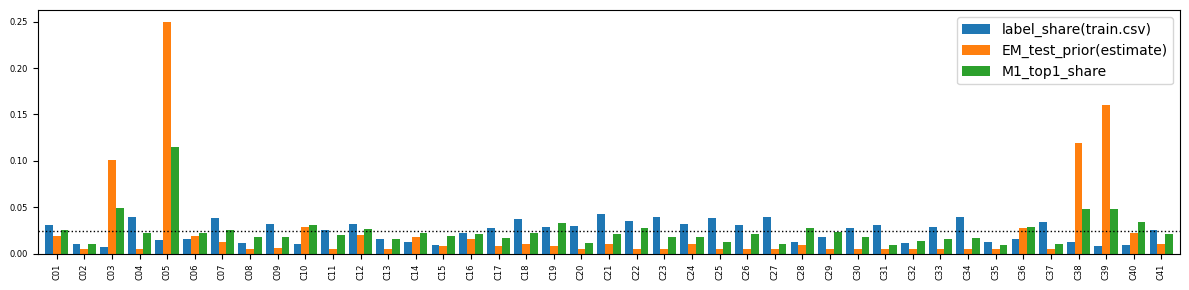

In [9]:
slots = pd.Series(np.argsort(-P_m1, axis=1)[:, :3].ravel()).value_counts().reindex(range(K)).fillna(0)
share_big = slots[[cls_idx[c] for c in big]].sum() / slots.sum()
print("(a) large-quota classes: %d | share of verified samples %.1f%% | share of all train recordings %.1f%%" % (
      len(big), 100*tab.loc[big,'verified'].sum()/tab.verified.sum(), 100*tab.loc[big,'total'].sum()/tab.total.sum()))
print("(b) Model 1: share of all top-3 slots on the test set going to these classes: %.1f%%  (balanced test would give %.1f%%)" % (100*share_big, 100*len(big)/K))
Pc1 = sharpen(P_m1, TF89); pi_hat1 = em_prior(Pc1)
cmp_ = pd.DataFrame({"verified_n": tab.verified.values, "label_share(train.csv)": pi_target, "EM_test_prior(estimate)": pi_hat1,
                     "M1_top1_share": np.bincount(P_m1.argmax(1), minlength=K) / len(P_m1)}, index=classes)
print("(c) correlation of the EM estimate with class-size share: %.2f  (uniform would be %.3f per class)" % (np.corrcoef(cmp_.iloc[:, 1], cmp_.iloc[:, 2])[0, 1], 1/K))
display(cmp_.round(3).T)
fig, ax = plt.subplots(figsize=(12, 3)); cmp_.iloc[:, 1:].plot.bar(ax=ax, width=.85)
ax.axhline(1 / K, color="k", ls=":", lw=1); ax.tick_params(labelsize=6); plt.tight_layout(); plt.show()

Interpretation guide: if the EM estimate tracks the class-size share, a class-size-proportional test is *plausible*; if it hugs the dotted uniform line, a balanced test is plausible. Neither is proven — the leaderboard is the only judge. The final models use a **tempered** correction (prior^0.5) as a hedge, and the model-selection score averages the skewed, class-size and uniform views so that no single assumption decides the outcome.

## 6. How noisy are the unchecked labels? (estimates only)

Verified-only models (cross-validated, so they never saw the unchecked samples) score the unchecked recordings; EM over the true label then *estimates* a noise matrix and per-class label purity. The classifier is weak (CV top-1 ≈ the number printed below), so these are rough estimates — useful for deciding which samples to trust, not facts about the dataset.

unchecked samples: 4984 | top-1 of the verified-only model agrees with the given label on 33.9%
EM *estimate* of the share of correct unchecked labels: 45.7% (rough; depends on classifier quality)
verified-CV top-1 accuracy of the same model family: 64.7%


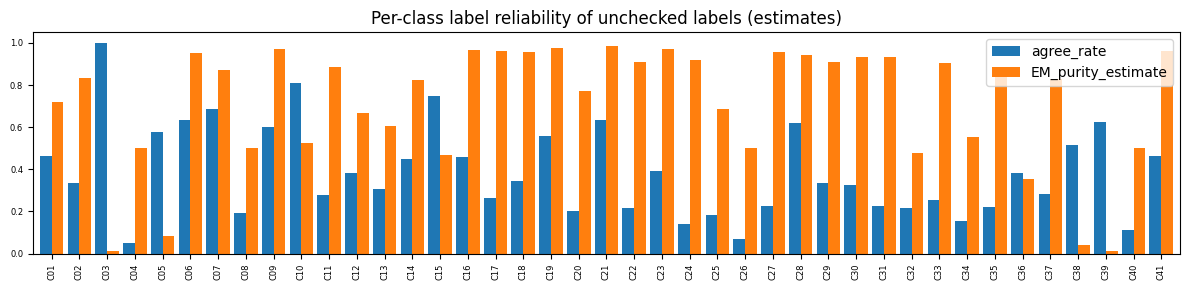

,unchecked_n,agree_rate,EM_purity_estimate
C03,2,1.000,0.012
C39,8,0.625,0.013
C38,29,0.517,0.043
C05,40,0.575,0.082
C36,47,0.383,0.354
C15,44,0.750,0.469
C32,56,0.214,0.476
C26,163,0.067,0.500


In [10]:
st = ST1[("F89", "orig", SEEDS[0])]
Pu_mean = np.mean(st["Pu"], axis=0); Pu_cal = sharpen(Pu_mean, TF89)
T, Q, pi_u = em_noise(Pu_cal, yu); purity = np.diag(T)
print("unchecked samples: %d | top-1 of the verified-only model agrees with the given label on %.1f%%" % (len(yu), 100*(Pu_mean.argmax(1) == yu).mean()))
print("EM *estimate* of the share of correct unchecked labels: %.1f%% (rough; depends on classifier quality)" % (100*(pi_u*purity).sum()/pi_u.sum()))
print("verified-CV top-1 accuracy of the same model family: %.1f%%" % (100*(st["oof"].argmax(1) == yv).mean()))
per_class = pd.DataFrame({"unchecked_n": tab.unchecked.values, "agree_rate": [(Pu_mean.argmax(1)[yu == k] == k).mean() if (yu == k).any() else np.nan for k in range(K)],
                          "EM_purity_estimate": purity}, index=classes)
fig, ax = plt.subplots(figsize=(12, 3)); per_class[["agree_rate", "EM_purity_estimate"]].plot.bar(ax=ax, width=.85)
ax.set_title("Per-class label reliability of unchecked labels (estimates)"); ax.tick_params(labelsize=6); plt.tight_layout(); plt.show()
display(per_class.sort_values("EM_purity_estimate").head(8).round(3))

## 7. Model 2 — add filtered unchecked data, correct the prior

The baseline used 620 of 5,604 training recordings. Unchecked recordings are added back only when there is reason to trust them:

* **`agree`** — keep a sample if a verified-only model (trained on the training fold only) ranks the *given* label first (or within top-2 above a probability floor);
* **`em`** — keep a sample if the EM posterior that its given label is true is ≥ a threshold (weight = that posterior; the EM temperature is fitted on the *other* folds only).

Kept samples get a reduced sample weight (verified = 1). The unchecked pool is disjoint from the validation fold and the filter never sees the validation fold.

**Selection protocol:** every configuration is evaluated on **both CV seeds**. The selection score for one seed is `sel = mean(plain, w_em0.5, u_em0.5)`; the configuration is ranked by `robust = mean over seeds − 0.5·|seed difference|`, so a configuration that is great on one seed and mediocre on the other loses to a consistent one. `verified_only` is a candidate too (= "unchecked data does not help").

In [11]:
CONFIGS = {
    "agree_r1_w0.5":      dict(method="agree", max_rank=1, w=0.5),
    "agree_r2_t.15_w0.5": dict(method="agree", max_rank=2, tau=0.15, w=0.5),
    "em_q0.6_w1.0":       dict(method="em", q_min=0.6, w=1.0),
}
RES = {}     # (feat, cfg_name or 'verified_only', seed) -> dict(oof, n_keep, rep)
def run_grid(feat, kind):
    for seed in SEEDS:
        st = get_st(feat, kind, seed)
        RES[(feat, "verified_only", seed)] = dict(oof=st["oof"], n_keep=0, rep=cv_report(st["oof"], st["splits"]))
        for name, cfg in CONFIGS.items():
            t0 = time.time(); oof, nk = stage2(feat, kind, st, cfg)
            RES[(feat, name, seed)] = dict(oof=oof, n_keep=nk, rep=cv_report(oof, st["splits"]))
            print(f"{feat:5s} seed {seed:5d} {name:20s} kept≈{nk:6.0f}  sel={sel(RES[(feat, name, seed)]['rep'], True):.4f}  ({time.time()-t0:.0f}s)")

def grid_table(feat):
    rows = []
    for name in ["verified_only"] + list(CONFIGS):
        sc = [sel(RES[(feat, name, sd)]["rep"], True) for sd in SEEDS]
        row = dict(config=name, n_unchecked_kept=np.mean([RES[(feat, name, sd)]["n_keep"] for sd in SEEDS]))
        row.update({f"sel_seed{sd}": v for sd, v in zip(SEEDS, sc)})
        row.update(mean=np.mean(sc), seed_gap=abs(sc[0] - sc[1]), robust=np.mean(sc) - 0.5 * abs(sc[0] - sc[1]))
        for k in ("plain", "w_em0.5", "u_em0.5"): row[k + "_avg"] = np.mean([RES[(feat, name, sd)]["rep"][k] for sd in SEEDS])
        rows.append(row)
    return pd.DataFrame(rows).set_index("config").sort_values("robust", ascending=False)

run_grid("F89", "orig")
GT_F89 = grid_table("F89"); display(GT_F89.round(4))

F89   seed    42 agree_r1_w0.5        kept≈  1632  sel=0.7023  (48s)
F89   seed    42 agree_r2_t.15_w0.5   kept≈  1557  sel=0.6990  (46s)
F89   seed    42 em_q0.6_w1.0         kept≈  2025  sel=0.6645  (61s)
F89   seed  2026 agree_r1_w0.5        kept≈  1632  sel=0.6925  (47s)
F89   seed  2026 agree_r2_t.15_w0.5   kept≈  1555  sel=0.6894  (45s)
F89   seed  2026 em_q0.6_w1.0         kept≈  2004  sel=0.6520  (59s)


,n_unchecked_kept,sel_seed42,sel_seed2026,mean,seed_gap,robust,plain_avg,w_em0.5_avg,u_em0.5_avg
config,,,,,,,,,
agree_r1_w0.5,1632.1,0.7023,0.6925,0.6974,0.0098,0.6925,0.7383,0.6850,0.6690
agree_r2_t.15_w0.5,1555.8,0.6990,0.6894,0.6942,0.0095,0.6894,0.7375,0.6825,0.6626
em_q0.6_w1.0,2014.8,0.6645,0.6520,0.6582,0.0125,0.6520,0.7352,0.6220,0.6175
verified_only,0.0,0.6088,0.5984,0.6036,0.0104,0.5984,0.7183,0.5358,0.5567


In [12]:
best2 = GT_F89.index[0]; cfg2 = None if best2 == "verified_only" else CONFIGS[best2]
print("Model 2 configuration (best `robust` on 89 features):", best2)
if best2 == "verified_only": print("-> no unchecked-data configuration was consistently better; Model 2 = Model 1 + calibrated EM prior correction only.")

def train_final(feat, kind, cfg, temp):
    Xv, Xu, Xt = XV[feat], XU[feat], XT[feat]
    if cfg is None: return fit_predict(Xv, yv, None, [Xt], kind, N_JOBS)[0], None
    Pu, = fit_predict(Xv, yv, None, [Xu], kind, N_JOBS)
    keep, w = select_unc(Pu, cfg, temp)
    Xa = np.vstack([Xv, Xu[keep]]); ya = np.concatenate([yv, yu[keep]]); wa = np.concatenate([np.ones(len(yv)), w[keep]])
    return fit_predict(Xa, ya, wa, [Xt], kind, N_JOBS)[0], keep

P_m2_raw, keep2 = train_final("F89", "orig", cfg2, TF89)
if keep2 is not None: print("unchecked samples used in final Model 2: %d of %d" % (keep2.sum(), len(yu)))
P_m2, pi_hat2 = finalize_probs(P_m2_raw, TF89, power=0.5)
sub2 = write_submission(P_m2, "submission_model2.csv")

Model 2 configuration (best `robust` on 89 features): agree_r1_w0.5
unchecked samples used in final Model 2: 1725 of 4984
saved /kaggle/working/model_files/submission_model2.csv (1592, 2)


## 8. Model 3 — richer features + wider ensemble

The baseline found that extra features *hurt* with only 620 samples. With more (filtered) training data they might help. Changes: the **rich feature block** (log-mel statistics, active-frame MFCC statistics, delta-MFCC, spectral flatness, onset strength/rate, RMS percentiles) and an ensemble for wide features (two RBF-SVMs, a more strongly regularised LR, 500-tree RF/ExtraTrees).

This is an **experiment, not an assumption**: the cell after the grid states whether the rich features beat the 89-feature configuration on *both* seeds, and the final submission choice (Section 10) only accepts Model 3 if they do.

In [13]:
run_grid("Frich", "rich")
GT_RICH = grid_table("Frich"); display(GT_RICH.round(4))

Frich seed    42 agree_r1_w0.5        kept≈  1743  sel=0.7368  (117s)
Frich seed    42 agree_r2_t.15_w0.5   kept≈  1659  sel=0.7274  (110s)
Frich seed    42 em_q0.6_w1.0         kept≈  2387  sel=0.6994  (167s)
Frich seed  2026 agree_r1_w0.5        kept≈  1749  sel=0.7215  (116s)
Frich seed  2026 agree_r2_t.15_w0.5   kept≈  1647  sel=0.7072  (107s)
Frich seed  2026 em_q0.6_w1.0         kept≈  2350  sel=0.6896  (162s)


,n_unchecked_kept,sel_seed42,sel_seed2026,mean,seed_gap,robust,plain_avg,w_em0.5_avg,u_em0.5_avg
config,,,,,,,,,
agree_r1_w0.5,1746.3,0.7368,0.7215,0.7292,0.0153,0.7215,0.7698,0.7150,0.7028
agree_r2_t.15_w0.5,1652.7,0.7274,0.7072,0.7173,0.0201,0.7072,0.7629,0.7011,0.6879
em_q0.6_w1.0,2368.2,0.6994,0.6896,0.6945,0.0099,0.6896,0.7606,0.6654,0.6575
verified_only,0.0,0.6389,0.6353,0.6371,0.0036,0.6353,0.7515,0.5727,0.5871


In [14]:
best3 = GT_RICH.index[0]; cfg3 = None if best3 == "verified_only" else CONFIGS[best3]
print("Model 3 configuration (best `robust` on the rich features):", best3)
TRICH = final_temp("Frich", "rich")
P_m3_raw, keep3 = train_final("Frich", "rich", cfg3, TRICH)
if keep3 is not None: print("unchecked samples used in final Model 3: %d of %d" % (keep3.sum(), len(yu)))
P_m3, pi_hat3 = finalize_probs(P_m3_raw, TRICH, power=0.5)
sub3 = write_submission(P_m3, "submission_model3.csv")
for tag, power in [("noprior", 0.0), ("prior_full", 1.0)]:           # variants for leaderboard probing of the prior correction
    Pv, _ = finalize_probs(P_m3_raw, TRICH, power); write_submission(Pv, f"submission_model3_{tag}.csv")
write_submission(adjust(sharpen(P_m3_raw, TRICH), pi_target ** 0.5), "submission_model3_prior_classsize.csv")

Model 3 configuration (best `robust` on the rich features): agree_r1_w0.5
unchecked samples used in final Model 3: 1838 of 4984
saved /kaggle/working/model_files/submission_model3.csv (1592, 2)
saved /kaggle/working/model_files/submission_model3_noprior.csv (1592, 2)
saved /kaggle/working/model_files/submission_model3_prior_full.csv (1592, 2)
saved /kaggle/working/model_files/submission_model3_prior_classsize.csv (1592, 2)


,id,label
0,c99ed9e0,C39 C13 C11
1,f7988da2,C39 C26 C13
2,af43e3af,C40 C41 C06
3,fbb23ad8,C05 C28 C19
4,3be2034b,C03 C27 C15
...,...,...
1587,01fccd98,C36 C08 C28
1588,e510bbdc,C36 C28 C39
1589,07f07dd4,C19 C05 C11
1590,1f4df05e,C24 C13 C40


### Do the rich features genuinely help? (checked on both seeds)

In [15]:
rows = []
for sd in SEEDS:
    a = max(sel(RES[("F89", n, sd)]["rep"], True) for n in ["verified_only"] + list(CONFIGS))
    b = max(sel(RES[("Frich", n, sd)]["rep"], True) for n in ["verified_only"] + list(CONFIGS))
    rows.append(dict(seed=sd, best_F89=a, best_Frich=b, difference=b - a))
rv = pd.DataFrame(rows).set_index("seed"); display(rv.round(4))
# the like-for-like comparison: the SAME configuration with both feature sets
same = pd.DataFrame({n: {f"{f}/seed{sd}": sel(RES[(f, n, sd)]["rep"], True) for f in ("F89", "Frich") for sd in SEEDS} for n in ["verified_only"] + list(CONFIGS)}).T
display(same.round(4))
RICH_HELPS = bool((rv["difference"] > 0).all())
print("rich features better on BOTH seeds (best config vs best config):", RICH_HELPS)
if not RICH_HELPS: print("-> not consistent: the simpler 89-feature pipeline is retained unless you override SUBMIT_CHOICE.")

,best_F89,best_Frich,difference
seed,,,
42,0.7023,0.7368,0.0345
2026,0.6925,0.7215,0.0290


,F89/seed42,F89/seed2026,Frich/seed42,Frich/seed2026
verified_only,0.6088,0.5984,0.6389,0.6353
agree_r1_w0.5,0.7023,0.6925,0.7368,0.7215
agree_r2_t.15_w0.5,0.6990,0.6894,0.7274,0.7072
em_q0.6_w1.0,0.6645,0.6520,0.6994,0.6896


rich features better on BOTH seeds (best config vs best config): True


## 9. Error analysis (Model 3 configuration, out-of-fold predictions, cross-fitted calibration)

Per-class MAP@3, the most frequent confusions, and the effect of recording length. These are properties of the *verified* validation folds only.

plain MAP@3 0.7742 | top-1 acc 0.719 | top-3 acc 0.842


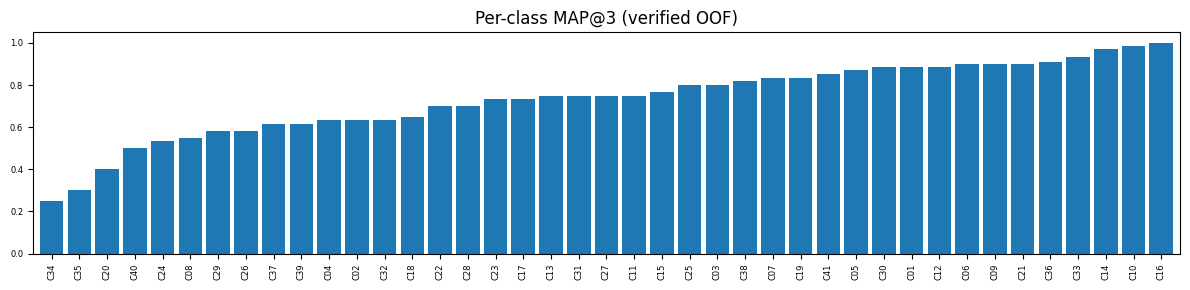

Weakest classes:


,C34,C35,C20,C40,C24,C08,C29,C26
MAP3,0.25,0.3,0.4,0.5,0.533,0.55,0.583,0.583
n_verified,10.00,10.0,10.0,10.0,10.000,10.00,10.000,10.000


Most frequent top-1 confusions:


,true,pred,count
0,C05,C19,4
1,C26,C19,4
2,C37,C17,4
3,C02,C38,3
4,C03,C27,3
5,C38,C14,3
6,C03,C21,2
7,C03,C25,2
8,C04,C05,2
9,C05,C26,2


MAP@3 by recording length (quintiles of verified durations):


,duration_range_s,MAP3,n
0,0.4-1.5,0.809,124
1,1.5-2.7,0.722,124
2,2.7-5.0,0.797,124
3,5.0-8.4,0.770,124
4,8.4-31.3,0.773,124


In [16]:
sd0 = SEEDS[0]; st3 = ST1[("Frich", "rich", sd0)]
oof3 = RES[("Frich", best3, sd0)]["oof"]; P3c = crossfit_cal(oof3, st3["splits"])
s3 = map3_s(yv, P3c)
pc = pd.DataFrame({"MAP3": [s3[yv == k].mean() for k in range(K)], "n_verified": tab.verified.values}, index=classes).sort_values("MAP3")
print("plain MAP@3 %.4f | top-1 acc %.3f | top-3 acc %.3f" % (s3.mean(), (P3c.argmax(1) == yv).mean(), np.mean([yv[i] in np.argsort(-P3c[i])[:3] for i in range(len(yv))])))
fig, ax = plt.subplots(figsize=(12, 3)); pc.MAP3.plot.bar(ax=ax, width=.85); ax.set_title("Per-class MAP@3 (verified OOF)"); ax.tick_params(labelsize=6); plt.tight_layout(); plt.show()
print("Weakest classes:"); display(pc.head(8).round(3).T)
conf = pd.crosstab(pd.Series(classes[yv], name="true"), pd.Series(classes[P3c.argmax(1)], name="pred_top1"))
pairs = [(a, b, conf.loc[a, b]) for a in conf.index for b in conf.columns if a != b and conf.loc[a, b] > 0]
print("Most frequent top-1 confusions:"); display(pd.DataFrame(sorted(pairs, key=lambda t: -t[2])[:12], columns=["true", "pred", "count"]))
dv = dur_tr[verified_mask]; qs = np.quantile(dv, [0, .2, .4, .6, .8, 1.0]); bin_ = np.clip(np.digitize(dv, qs[1:-1]), 0, 4)
print("MAP@3 by recording length (quintiles of verified durations):")
display(pd.DataFrame({"duration_range_s": [f"{qs[i]:.1f}-{qs[i+1]:.1f}" for i in range(5)], "MAP3": [s3[bin_ == i].mean() for i in range(5)], "n": [(bin_ == i).sum() for i in range(5)]}).round(3))

## 10. Evidence summary and submission choice

In [17]:
M = {"Model 1": ("F89", "verified_only", False), "Model 2": ("F89", best2, True), "Model 3": ("Frich", best3, True)}
rows = []
for m, (f, n, corr) in M.items():
    for sd in SEEDS:
        r = RES[(f, n, sd)]["rep"]
        rows.append(dict(model=m, features=f, config=n, seed=sd, plain_CV=r["plain"],
                         weighted_classsize=(r["w_em0.5"] if corr else r["w_raw"]), weighted_uniform=(r["u_em0.5"] if corr else r["u_raw"]),
                         selection_score=sel(r, corr), prior_corrected=corr))
EV = pd.DataFrame(rows); display(EV.round(4).set_index(["model", "seed"]))

# consistency-gated choice: a more complex model replaces the simpler one only if it is better on BOTH seeds
S = {m: [sel(RES[(f, n, sd)]["rep"], c) for sd in SEEDS] for m, (f, n, c) in M.items()}
chosen = "Model 1"
for cand in ("Model 2", "Model 3"):
    if all(a > b for a, b in zip(S[cand], S[chosen])): chosen = cand
FILES = {"Model 1": "submission_model1_baseline.csv", "Model 2": "submission_model2.csv", "Model 3": "submission_model3.csv"}
SUBMIT_CHOICE = "auto"      # "auto" = consistency-gated choice above; or set e.g. "Model 2" to force one
final_model = chosen if SUBMIT_CHOICE == "auto" else SUBMIT_CHOICE
pd.read_csv(OUT / FILES[final_model], dtype={"id": str}).to_csv(WORK / "submission.csv", index=False, lineterminator="\n")
print("consistency-gated choice:", chosen, "| written to submission.csv:", final_model, "(", FILES[final_model], ")")
print("All three model files are kept in", OUT, "- compare them on the leaderboard; do not trust the CV choice alone.")

LB = pd.DataFrame({"model": list(FILES), "file": list(FILES.values()), "kaggle_public_LB": [0.69479, np.nan, np.nan]}).set_index("model")
display(LB)    # fill in Models 2 and 3 after submitting

features         config  plain_CV  weighted_classsize  \
model   seed                                                         
Model 1 42        F89  verified_only    0.7263              0.6458   
        2026      F89  verified_only    0.7102              0.6261   
Model 2 42        F89  agree_r1_w0.5    0.7422              0.6918   
        2026      F89  agree_r1_w0.5    0.7344              0.6783   
Model 3 42      Frich  agree_r1_w0.5    0.7742              0.7235   
        2026    Frich  agree_r1_w0.5    0.7653              0.7065   

              weighted_uniform  selection_score  prior_corrected  
model   seed                                                      
Model 1 42              0.6603           0.6775            False  
        2026            0.6378           0.6580            False  
Model 2 42              0.6731           0.7023             True  
        2026            0.6649           0.6925             True  
Model 3 42              0.7127           0.7368             True  
        2026            0.6928           0.7215             True

consistency-gated choice: Model 3 | written to submission.csv: Model 3 ( submission_model3.csv )
All three model files are kept in /kaggle/working/model_files - compare them on the leaderboard; do not trust the CV choice alone.


,file,kaggle_public_LB
model,,
Model 1,submission_model1_baseline.csv,0.69479
Model 2,submission_model2.csv,NaN
Model 3,submission_model3.csv,NaN


In [18]:
# final format / ID audit of every CSV written
assert test_df["id"].is_unique and sample_df["id"].is_unique
assert set(test_df["id"]) == set(sample_df["id"]) and len(test_df) == EXPECTED_TEST
for f in [WORK / "submission.csv"] + sorted(OUT.glob("submission*.csv")):
    s = pd.read_csv(f, dtype={"id": str})
    assert list(s.columns) == ["id", "label"] and len(s) == EXPECTED_TEST and s["id"].is_unique
    assert set(s["id"]) == set(sample_df["id"]) == set(test_df["id"])
    assert all(1 <= len(v.split()) <= 3 and len(set(v.split())) == len(v.split()) and all(c in cls_idx for c in v.split()) for v in s["label"])
    print("OK ", f.relative_to(WORK), s.shape)

OK  submission.csv (1592, 2)
OK  model_files/submission_model1_baseline.csv (1592, 2)
OK  model_files/submission_model2.csv (1592, 2)
OK  model_files/submission_model3.csv (1592, 2)
OK  model_files/submission_model3_noprior.csv (1592, 2)
OK  model_files/submission_model3_prior_classsize.csv (1592, 2)
OK  model_files/submission_model3_prior_full.csv (1592, 2)
